# The hottest week of summer 2026 in Greece 🌡️
### Copernicus Climate Change Service · ERA5-Land · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/heat_era5land.ipynb)

The hottest week of summer 2026 in Greece was **22 to 28 August**. This notebook maps its hottest hour,
**Sunday 23 August at 15:00 in Athens**, from **ERA5-Land**, the Copernicus land reanalysis at about 9 km that ECMWF
produces for the European Union. ERA5-Land covers land only, so every island shows and the sea stays blank.

*In Google Colab? Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land?tab=download) on the Climate Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the hour and the area

In [4]:
AREA = [42.0, 19.0, 34.5, 30.0]            # north, west, south, east
YEAR, MONTH, DAY, HOUR = "2026", "08", "23", "12:00"   # UTC: 12 UTC = 15:00 in Athens in summer
CITIES = [("Athens", 37.984, 23.728), ("Thessaloniki", 40.640, 22.944), ("Patras", 38.246, 21.735),
          ("Heraklion", 35.339, 25.144), ("Rhodes", 36.434, 28.217)]

def label_cities(chart):
    for name, la, lo in CITIES:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get ERA5-Land

In [5]:
era = ekd.from_source("cds", "reanalysis-era5-land", {
    "variable": "2m_temperature", "year": YEAR, "month": MONTH, "day": DAY, "time": HOUR,
    "area": AREA, "data_format": "grib"}).to_xarray()
t2m = era[list(era.data_vars)[0]].squeeze() - 273.15
print(f"{float(t2m.min()):.0f} to {float(t2m.max()):.0f} °C across the land")

22 to 40 °C across the land


## 3 · Map it

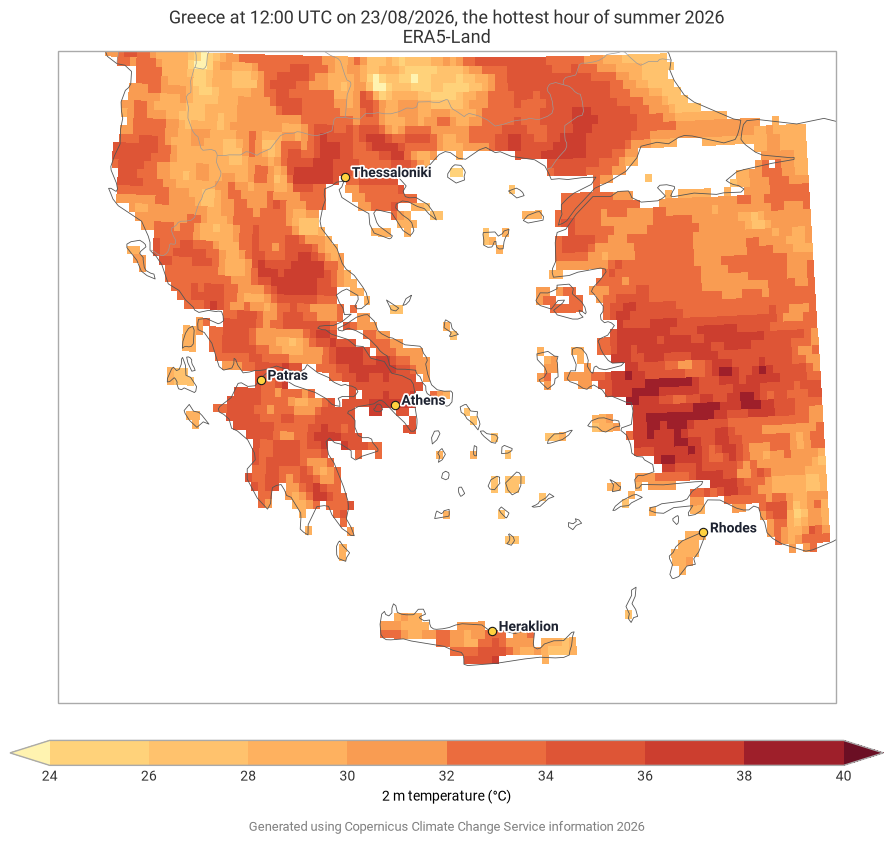

In [6]:
colors = ["#fff3b0", "#ffd27a", "#ffb562", "#f6904a", "#e8623a", "#c93a2e", "#9e1f2a", "#6b0f24"]
style = ekp.styles.Style(levels=[24, 26, 28, 30, 32, 34, 36, 38, 40], colors=colors, extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.pcolormesh(t2m, style=style)          # grid cells, so even the smallest islands show
chart.coastlines(linewidth=0.6); chart.borders(linewidth=0.5)
label_cities(chart)
chart.legend(label="2 m temperature (°C)")
chart.title(f"Greece at {HOUR} UTC on {DAY}/{MONTH}/{YEAR}, the hottest hour of summer 2026\nERA5-Land", fontsize=13)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("heat_era5land.png")
chart.show()

## 4 · Your turn 🌍

- **The night after:** `DAY, HOUR = "23", "23:00"`: the mainland cools fast, the islands stay warm.
- **Another summer:** change `YEAR`. ERA5-Land goes back to 1950.
- **Feels-like heat:** add `"2m_dewpoint_temperature"` and compute the heat index with earthkit-meteo.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)